TODO :
- Decide what one row represents and write it down (for example: a repository, a film, a weather station, or an article). As Exercises 6 and 7 showed, this choice determines what your clusters mean.

    - A row is a clip, joined with the information of its channel and its game. Our features are the views relative to the game, the hour of the day, language, game, channel content labels and tag buckets

- Build the feature table X. The table below suggests features for each project source. Use one-hot encoding for categories, take the log of skewed counts, and use TF-IDF for text columns.

- Standardise the features ((feat - feat.mean()) / feat.std()), then cluster for two or three values of 𝑘. If you compute silhouette scores on more than a few thousand rows, pass sample_size=10_000 to silhouette_score so that the 𝑂(𝑛2) pairwise distance calculation does not hang.

- Print the cluster profile table and give every cluster a short descriptive name. Put the cluster names and interpretation in your report, and the full profile table in the appendix.

- Inspect any small or hard-to-name cluster. As with the 14 broken-meter trips in Exercise 6, an unusual cluster often reveals a data-quality issue missed in the previous weeks.

In [49]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 100)
sns.set_theme(style="whitegrid")

CLEAN_DATA_DIR = Path.cwd().parent / "data/clean/"

clean_games_path = CLEAN_DATA_DIR / "games_cleaned.parquet"
clean_clips_path = CLEAN_DATA_DIR / "clips_cleaned.parquet"
clean_channels_path = CLEAN_DATA_DIR / "channels_cleaned.parquet"

cgdf = pd.read_parquet(clean_games_path)
cdf = pd.read_parquet(clean_clips_path)
chdf = pd.read_parquet(clean_channels_path)

### Feature selection

First we decide what one row represents. We have three tables (clips, channels, games) and we join them, so one row is a clip with the information of its channel and its game. After cleaning there are 1,892 clips, and the table has 45 columns after encoding.

- **Views:** `log(1 + view_count)`, standardised inside each game (see below).
- **Time:** the hour of creation as a circle (sin and cos, so that 23h and 1h are close) and a weekend flag.
- **Flags:** `is_featured` and `is_branded_content`.
- **Language and game:** the language of the clip (the six most common, the rest as "other") and the game, both one-hot.
- **Channel content:** the content classification labels (one-hot) and six buckets built from the channel tags.

We do not use the title (the embeddings are in the `mining_titles` notebook) or the duration (see the check after the clustering).

## Building the feature table

**Content labels.** One column per label, plus `label_none` when the channel has no label.

**Tags.** There are 1,365 different non-language tags, most of them rare, and they are written in the language of the channel ("win" is "ganar" in Spanish and "vincere" in Italian). One column per tag would group the clips by alphabet and not by concept. We remove the language tags and map the most common concepts by hand to six buckets: drops, competitive, vtuber/anime, irl/chill, roleplay/multiplayer and persona. The mapping is subjective, but the columns mean the same in every language and they do not dominate the table.

In [50]:
import re

# content classification labels: one-hot, label_none if the channel has no label
label_set = {
    label
    for text in chdf["content_classification_labels"].dropna()
    for label in re.findall(r"'([^']+)'", str(text))
    if label.strip() not in ("[]", "")
}
for label in label_set:
    chdf[f"label_{label}"] = (
        chdf["content_classification_labels"]
        .astype("string")
        .str.contains(f"'{label}'", regex=False, na=False)
        .astype("int8")
    )
label_cols = [f"label_{label}" for label in label_set]
chdf["label_none"] = (chdf[label_cols].sum(axis=1) == 0).astype("int8")
chdf = chdf.drop(columns=["content_classification_labels"])

# tags: remove the language tags and keep the concept tags
def parse_tags(val):
    if val is None or pd.isna(val):
        return []
    return [t.strip().lower() for t in re.findall(r"'([^']+)'", str(val)) if t.strip()]

lang_tags_to_remove = {
    "english", "русский", "español", "日本語", "deutsch", "français",
    "português", "italiano", "polski", "türkçe", "한국어", "chinese中文",
    "中文", "ukr", "українська", "عربي", "čeština", "magyar", "suomi", "العربية", "arabic", "nederlands"
}
chdf["concept_tags"] = chdf["tags"].apply(parse_tags).apply(
    lambda tags: [t for t in tags if t not in lang_tags_to_remove]
)
print(f"Total unique non-language tags: {chdf['concept_tags'].explode().nunique()}")

# six buckets built by hand from the most common concept tags
SUPER_TAGS = {
    "tag_drops": ["drop", "掉宝", "дроп"],
    "tag_competitive": ["rank", "comp", "esport", "tourn", "pvp", "fps", "tryhard", "eternus"],
    "tag_vtuber_anime": ["vtub", "anime", "png", "weeb", "otaku", "manga"],
    "tag_irl_chill": ["irl", "chill", "chat", "asmr", "vibe", "travel", "food", "music", "雑談", "funny", "cozy", "lifestyle", "cooking"],
    "tag_rp_multiplayer": ["nopixel", "roleplay", "gtarp", "gta5rp", "multiplayer", "coop", "ストグラ", "squad"],
    "tag_persona": ["girl", "adhd", "lgbt", "feet", "bald", "educational"],
}
for col_name, keywords in SUPER_TAGS.items():
    chdf[col_name] = chdf["concept_tags"].apply(
        lambda tag_list: int(any(kw in tag for tag in tag_list for kw in keywords))
    )

# number of channels in each bucket
print(chdf[list(SUPER_TAGS.keys())].sum())

Total unique non-language tags: 1365
tag_drops             303
tag_competitive        77
tag_vtuber_anime       50
tag_irl_chill         107
tag_rp_multiplayer     40
tag_persona            53
dtype: int64


In [51]:
# game name from the clip's own game_id
game_map = dict(zip(cgdf["id"], cgdf["name"]))
cdf["game_name"] = cdf["game_id"].map(game_map)

chdf_cols_to_keep = (
    ["broadcaster_id", "is_branded_content"]
    + label_cols + ["label_none"]
    + list(SUPER_TAGS.keys())
)
df = pd.merge(cdf, chdf[chdf_cols_to_keep], on="broadcaster_id", how="left")

# numeric features
X = pd.DataFrame(index=df.index)
X["log_view_count"] = np.log1p(df["view_count"].astype(float))
X["is_featured"] = df["is_featured"].fillna(False).astype(int)
X["is_branded_content"] = df["is_branded_content"].fillna(False).astype(int)
X["is_weekend"] = (df["created_at"].dt.dayofweek >= 5).astype(int)
hour = df["created_at"].dt.hour + df["created_at"].dt.minute / 60
X["hour_sin"] = np.sin(2 * np.pi * hour / 24)
X["hour_cos"] = np.cos(2 * np.pi * hour / 24)

# language (top 6 + other) and game, one-hot
top_langs = ["en", "ru", "ja", "de", "es", "fr"]
lang_grouped = df["language"].where(df["language"].isin(top_langs), other="other")
lang_dummies = pd.get_dummies(lang_grouped, prefix="lang", dtype=int)
game_dummies = pd.get_dummies(df["game_name"], prefix="game", dtype=int)

tag_and_label_cols = label_cols + ["label_none"] + list(SUPER_TAGS.keys())
X = pd.concat(
    [X, lang_dummies, game_dummies, df[tag_and_label_cols].fillna(0).astype(int)],
    axis=1
)
print(f"Final feature matrix X shape: {X.shape}")

Final feature matrix X shape: (1892, 45)


### Views relative to the game

The views depend a lot on the game, so with raw views the clusters follow the game: the completeness against the game is 0.37, against 0.06 when the views are standardised inside each game (check below, k = 3). We therefore use the z-score of the log views within each game.

The binary columns are multiplied by 0.5, so that the many one-hot columns do not dominate the two continuous features (views and hour), and each row is normalised to length 1.

In [52]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, completeness_score, silhouette_score
from sklearn.preprocessing import StandardScaler, normalize

game = df["game_name"].fillna("unknown")

# views as a z-score inside each game
X_rel = X.copy()
X_rel["log_view_count"] = X_rel["log_view_count"].groupby(df["game_id"]).transform(
    lambda s: (s - s.mean()) / s.std()
)
cols_to_scale = ["log_view_count"]
cyclic_cols = ["hour_sin", "hour_cos"]
binary_cols = [c for c in X.columns if c not in cols_to_scale + cyclic_cols]
BINARY_WEIGHT = 0.5

def build(data):
    Z = data.copy()
    Z[cols_to_scale] = StandardScaler().fit_transform(Z[cols_to_scale])
    Z = Z.fillna(0)
    Z[binary_cols] *= BINARY_WEIGHT
    return normalize(Z)

# do the clusters follow the game? raw views against views within the game
for name, data in [("views raw", X), ("views within game", X_rel)]:
    labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(build(data))
    print(name,
          "| completeness vs game:", round(completeness_score(game, labels), 2),
          "| log_views by cluster:", X.groupby(labels)["log_view_count"].mean().round(2).tolist(),
    )

views raw | completeness vs game: 0.37 | log_views by cluster: [8.79, 9.28, 7.08]
views within game | completeness vs game: 0.06 | log_views by cluster: [9.12, 7.97, 8.26]


## Clustering

We run k-means for k = 2 to 12 on the table above. For each k we compute the inertia, the silhouette, the stability across 5 random seeds (mean ARI between the runs) and the completeness against the game, which should stay low: if it does not, the clusters only recover the game.

 k  inertia  silhouette  stability_ari  completeness_game
 2   1262.9       0.203          1.000               0.00
 3   1044.8       0.205          0.995               0.06
 4    902.1       0.205          1.000               0.06
 5    840.7       0.179          0.965               0.07
 6    791.1       0.157          0.925               0.07
 7    757.3       0.143          0.792               0.07
 8    724.7       0.134          0.967               0.07
 9    701.3       0.130          0.806               0.07
10    680.5       0.129          0.749               0.07
11    666.4       0.119          0.733               0.07
12    654.0       0.117          0.664               0.09


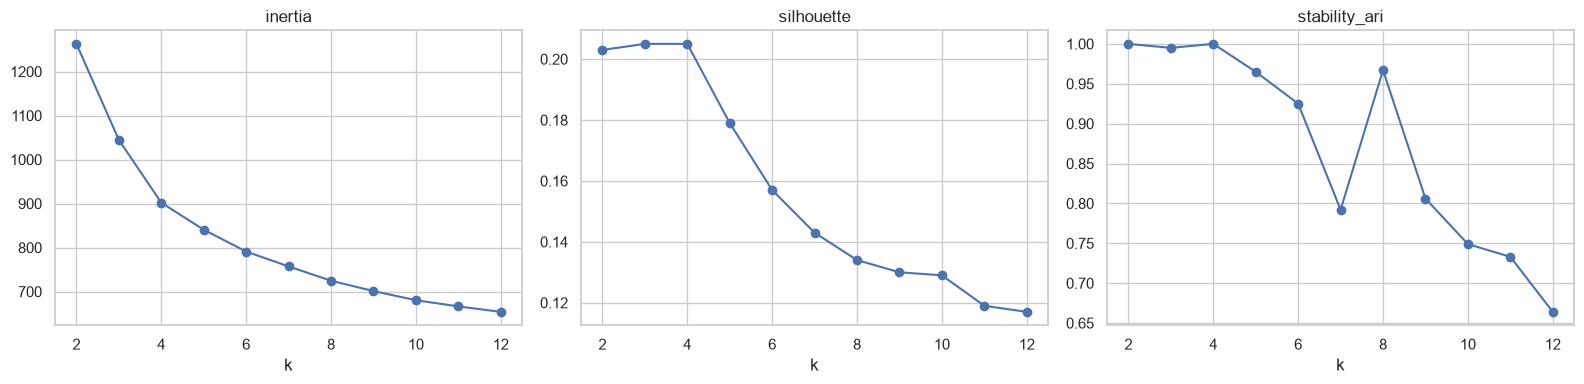

In [53]:
Z = build(X_rel)

rows = []
for k in range(2, 13):
    fits = [KMeans(n_clusters=k, random_state=s, n_init=10).fit(Z) for s in range(5)]
    ari = np.mean([adjusted_rand_score(fits[i].labels_, fits[j].labels_)
                   for i in range(5) for j in range(i + 1, 5)])
    rows.append({
        "k": k,
        "inertia": round(fits[0].inertia_, 1),
        "silhouette": round(silhouette_score(Z, fits[0].labels_), 3),
        "stability_ari": round(ari, 3),
        "completeness_game": round(completeness_score(game, fits[0].labels_), 2),
    })
res = pd.DataFrame(rows)
print(res.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["inertia", "silhouette", "stability_ari"]):
    ax.plot(res["k"], res[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

In [54]:
BEST_K = 4
km = KMeans(n_clusters=BEST_K, random_state=42, n_init=10).fit(Z)
df["cluster"] = km.labels_

# profile: mean of each feature per cluster (views in z-score within the game)
profile = X_rel.groupby(df["cluster"]).mean().round(2).T.rename(index={"log_view_count": "views_z_in_game"})
profile.loc["views_raw_median"] = df.groupby("cluster")["view_count"].median()
profile.loc["CLUSTER_SIZE"] = df["cluster"].value_counts().sort_index()

# circular mean of the hour of each cluster
angle = np.arctan2(X["hour_sin"].groupby(df["cluster"]).mean(),
                   X["hour_cos"].groupby(df["cluster"]).mean())
profile.loc["mean_hour_utc"] = ((angle % (2 * np.pi)) * 24 / (2 * np.pi)).round(1)
print(profile.to_string())

cluster                                    0       1        2       3
views_z_in_game                        -0.54    -0.4     1.43   -0.39
is_featured                             0.06     0.1     0.09     0.1
is_branded_content                       0.1    0.15     0.09    0.09
is_weekend                              0.29    0.26     0.29    0.33
hour_sin                               -0.89    0.03    -0.49    0.29
hour_cos                                0.11   -0.84     -0.0    0.75
lang_de                                  0.1    0.05     0.07    0.03
lang_en                                  0.4    0.26     0.46    0.69
lang_es                                 0.11    0.01      0.1    0.04
lang_fr                                 0.03    0.01     0.02    0.04
lang_ja                                  0.1    0.39     0.13     0.1
lang_other                               0.1    0.11     0.09    0.07
lang_ru                                 0.17    0.15     0.14    0.03
game_AION 2         

In [55]:
# language of the clips in each cluster (languages with at least 30 clips)
ct = pd.crosstab(df["language"], df["cluster"])
big = ct[ct.sum(axis=1) >= 30]
print(big.div(big.sum(axis=1), axis=0).round(2).assign(n=big.sum(axis=1)))

# duration was left out of the features: is it related to the views or to the clusters?
print("\nSpearman, duration vs views z-score:", round(df["duration"].corr(X_rel["log_view_count"], method="spearman"), 3))
print(df.groupby("cluster")["duration"].agg(["mean", "median"]).round(1))

cluster      0     1     2     3    n
language                             
ar        0.39  0.23  0.13  0.26   31
de        0.47  0.19  0.24  0.10  124
en        0.30  0.15  0.25  0.30  825
es        0.48  0.05  0.35  0.11  133
fr        0.37  0.14  0.22  0.27   49
ja        0.17  0.55  0.17  0.10  336
pt        0.51  0.14  0.11  0.24   37
ru        0.42  0.29  0.25  0.04  248
zh        0.22  0.44  0.28  0.06   79

Spearman, duration vs views z-score: -0.045
         mean  median
cluster              
0        25.8    22.5
1        27.9    25.0
2        26.0    22.0
3        27.4    25.8


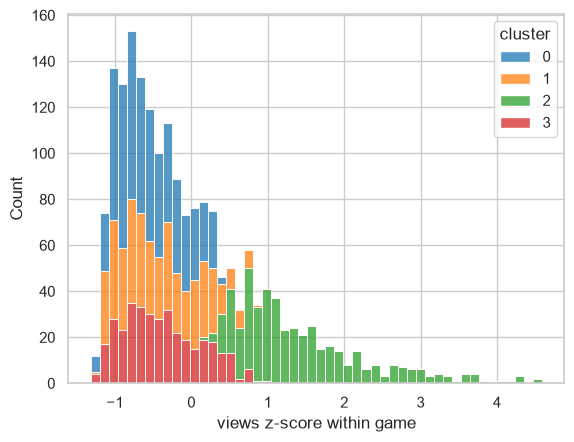

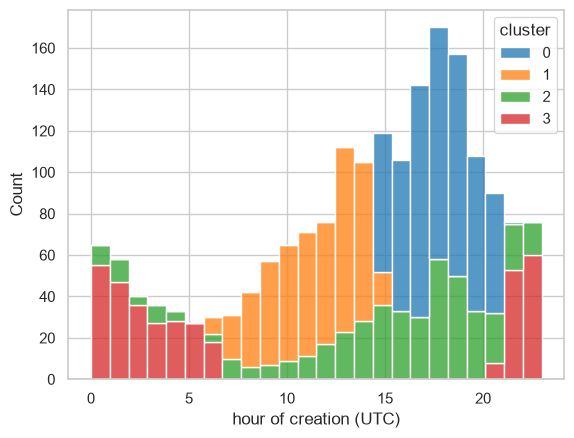

In [56]:
# views (z-score within the game) and hour of creation, stacked by cluster
sns.histplot(x=X_rel["log_view_count"], hue=df["cluster"], palette="tab10", bins=50, multiple="stack")
plt.xlabel("views z-score within game")
plt.show()

df["hour"] = df["created_at"].dt.hour
sns.histplot(data=df, x="hour", hue="cluster", multiple="stack", bins=24, palette="tab10")
plt.xlabel("hour of creation (UTC)")
plt.show()

## Evaluation

### Design and choice of k

One row is a clip: 1,892 clips and 45 features (see Feature selection). The distance is Euclidean on rows of length 1. The views z-score and the hour (sin, cos) have weight 1 and the binary columns 0.5, a weight chosen by hand and not tuned.

The silhouette is 0.20 for k = 2, 3 and 4 (0.203, 0.205, 0.205) and falls after that (0.179 at k = 5, about 0.12 at k = 12). The stability across seeds is 1.00 at k = 4 and lower for larger k (0.66 at k = 12), and the completeness against the game stays at 0.09 or less for every k. We keep k = 4: same silhouette as k = 2 and 3, perfect stability, and the largest k before the silhouette falls. The silhouette is low for every k, so no k gives well separated clusters.

### Clusters (k = 4)

| Cluster | Name | Clips | Mean hour (UTC) | Views z | Median views | EN | JA | RU | ES |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | Popular clips, all hours | 456 | 18.0 (spread) | +1.43 | 10,700 | 0.46 | 0.13 | 0.14 | 0.10 |
| 1 | Early hours, Asian languages | 472 | 11.9 | −0.40 | 4,300 | 0.26 | 0.39 | 0.15 | 0.01 |
| 0 | Afternoon and evening hours, European languages | 605 | 18.5 | −0.54 | 3,400 | 0.40 | 0.10 | 0.17 | 0.11 |
| 3 | Night hours, English | 359 | 1.4 | −0.39 | 3,400 | 0.69 | 0.10 | 0.03 | 0.04 |

- **Cluster 2** is the upper tail of the views: 24% of the clips, 1.4 standard deviations above the average of their game. In the histogram it starts at a z-score of about 0.5, and its clips are created at every hour, so its mean hour has no meaning.
- **Clusters 1, 0 and 3** have the same views (z-score −0.40, −0.54, −0.39) and are three arcs of the day (histogram: about 7h to 15h, 15h to 21h and 21h to 6h UTC) with a different language mix: 55% of the Japanese and 44% of the Chinese clips are in cluster 1, 42% to 51% of the Russian, German, Spanish and Portuguese clips are in cluster 0, and cluster 3 is 69% English with only 4% of the Russian clips.
- A reasonable reading is that each arc is the evening of an audience time zone (East Asia, Europe, the Americas). We cannot check it: the hour is in UTC and the language is the one declared by the channel. The language is also a clustering feature, so the match is not independent evidence. The arcs cut a continuous cycle: the hour histogram has no gap between them and peaks around 17h to 19h.
- The other features do not separate the clusters: flags (`is_featured` 0.06 to 0.10, `is_branded_content` 0.09 to 0.15, weekend 0.26 to 0.33), labels (`label_none` 0.76 to 0.79), tag buckets (at most 0.10 of difference) and games (the largest difference is Rust and Street Fighter 6, 11% of cluster 1 against 2% to 5% of the others).

### Robustness and limitations

- **Seeds:** the ARI between 5 runs is 1.00 for k = 4, so k-means always finds the same partition. We did not resample the clips, so we do not know how the partition changes with the sample.
- **Weights and tags:** the weight of 0.5 and the six tag buckets are manual choices. We did not test other weights or remove the channel columns to check that the partition stays the same.
- **Duration:** it is not used. Its Spearman correlation with the views z-score is −0.045 and the mean duration is similar in the four clusters (25.8 to 27.9 seconds).
- **`irl` keyword:** it is matched as a substring of the tags, so `girl` also falls in `tag_irl_chill` (and in `tag_persona`) and the two buckets overlap. The tag buckets are almost the same in all clusters, so we do not expect a change, but we did not run it again.
- **Views are an outcome** and here also a clustering axis, so cluster 2 is the high-views group by construction and not a finding. We have no channel size, which probably explains most of the views.
- The sample is the 100 most viewed clips per game in September, so "popular" means popular among clips that were already successful. The clips of a channel share its labels and tags, so the rows are not independent.

### Conclusion

With one row per clip, k-means (k = 4, silhouette 0.205) finds two things: a group of popular clips (24% of the clips, created at all hours) and three arcs of the day with a different language mix (Asian languages, European languages, English). The three arcs have the same views, so the hour does not change how many views a clip gets, and the game, the channel labels, the tag buckets and the flags do not separate the clips. We did not find types of clips: the partition comes from the two continuous features and from the weights.